## Лабораторна робота №2: Зниження розмірності, кластеризація та класифікація текстових даних
### ФБ-61мп Невмержицька Дар'я

### **Мета роботи:** Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.  
### Хід роботи: 

Імпорт необхідних бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.metrics import make_scorer

import time
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score



**Частина 1**. Зниження розмірності та візуалізація даних

Завдання: Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
Застосуйте `sklearn.decomposition.PCA` для зниження розмірності даних. На отриманих даних навчіть один з алгоритмів класифікації з Lab 1 та порівняйте результати класифікації "до" та "після" PCA.
Зробіть висновки: як PCA вплинув на якість класифікації;  наскільки вдалося зменшити кількість ознак;  чи змінився час навчання моделі.
Для того самого датасету застосуйте `sklearn.manifold.TSNE` для зниження розмірності до 2D. Візуалізуйте отримані дані, використовуючи кольори для позначення класів, та поясніть результат.

1.1. Завантаження датасету

In [2]:
df = pd.read_csv("cybersecurity_attacks.csv")

print("Розмір датасету:", df.shape)
print("\nНазви колонок:")
print(df.columns.tolist())

df.head()
#df_encoded.sample(5)

Розмір датасету: (40000, 25)

Назви колонок:
['Timestamp', 'Source IP Address', 'Destination IP Address', 'Source Port', 'Destination Port', 'Protocol', 'Packet Length', 'Packet Type', 'Traffic Type', 'Payload Data', 'Malware Indicators', 'Anomaly Scores', 'Alerts/Warnings', 'Attack Type', 'Attack Signature', 'Action Taken', 'Severity Level', 'User Information', 'Device Information', 'Network Segment', 'Geo-location Data', 'Proxy Information', 'Firewall Logs', 'IDS/IPS Alerts', 'Log Source']


,Timestamp,Source IP Address,Destination IP Address,Source Port,Destination Port,Protocol,Packet Length,Packet Type,Traffic Type,Payload Data,...,Action Taken,Severity Level,User Information,Device Information,Network Segment,Geo-location Data,Proxy Information,Firewall Logs,IDS/IPS Alerts,Log Source
0,2023-05-30 06:33:58,103.216.15.12,84.9.164.252,31225,17616,ICMP,503,Data,HTTP,Qui natus odio asperiores nam. Optio nobis ius...,...,Logged,Low,Reyansh Dugal,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment A,"Jamshedpur, Sikkim",150.9.97.135,Log Data,NaN,Server
1,2020-08-26 07:08:30,78.199.217.198,66.191.137.154,17245,48166,ICMP,1174,Data,HTTP,Aperiam quos modi officiis veritatis rem. Omni...,...,Blocked,Low,Sumer Rana,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment B,"Bilaspur, Nagaland",NaN,Log Data,NaN,Firewall
2,2022-11-13 08:23:25,63.79.210.48,198.219.82.17,16811,53600,UDP,306,Control,HTTP,Perferendis sapiente vitae soluta. Hic delectu...,...,Ignored,Low,Himmat Karpe,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,Segment C,"Bokaro, Rajasthan",114.133.48.179,Log Data,Alert Data,Firewall
3,2023-07-02 10:38:46,163.42.196.10,101.228.192.255,20018,32534,UDP,385,Data,HTTP,Totam maxime beatae expedita explicabo porro l...,...,Blocked,Medium,Fateh Kibe,Mozilla/5.0 (Macintosh; PPC Mac OS X 10_11_5; ...,Segment B,"Jaunpur, Rajasthan",NaN,NaN,Alert Data,Firewall
4,2023-07-16 13:11:07,71.166.185.76,189.243.174.238,6131,26646,TCP,1462,Data,DNS,Odit nesciunt dolorem nisi iste iusto. Animi v...,...,Blocked,Low,Dhanush Chad,Mozilla/5.0 (compatible; MSIE 5.0; Windows NT ...,Segment C,"Anantapur, Tripura",149.6.110.119,NaN,Alert Data,Firewall


1.2. Визначення ознак і цільової змінної

In [3]:
features = [
    "Source Port",
    "Destination Port",
    "Protocol",
    "Packet Length",
    "Packet Type",
    "Traffic Type",
    "Malware Indicators",
    "Anomaly Scores",
    "Severity Level",
    "Network Segment"
]

target = "IDS/IPS Alerts"

X = df[features].copy()
y = df[target].eq("Alert Data").astype(int)

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

print("\nРозподіл класів:")
print(y.value_counts().sort_index())

print("\nПозначення класів:")
print("0 — Missing")
print("1 — Alert Data")

df.sample(5)

Розмір X: (40000, 10)
Розмір y: (40000,)

Розподіл класів:
IDS/IPS Alerts
0    20050
1    19950
Name: count, dtype: int64

Позначення класів:
0 — Missing
1 — Alert Data


,Timestamp,Source IP Address,Destination IP Address,Source Port,Destination Port,Protocol,Packet Length,Packet Type,Traffic Type,Payload Data,...,Action Taken,Severity Level,User Information,Device Information,Network Segment,Geo-location Data,Proxy Information,Firewall Logs,IDS/IPS Alerts,Log Source
20501,2022-10-05 14:39:33,52.242.253.127,120.251.129.195,16310,27419,TCP,811,Control,DNS,Consequatur repudiandae aut. Odit magnam culpa...,...,Logged,Low,Vardaniya Lata,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,Segment B,"Srikakulam, Bihar",NaN,NaN,NaN,Firewall
4813,2021-09-18 13:17:57,75.179.187.172,30.227.86.101,5838,10160,ICMP,311,Data,FTP,Pariatur nulla iure est illo. Qui odio fugit o...,...,Logged,High,Hunar Tandon,Mozilla/5.0 (Macintosh; U; PPC Mac OS X 10_8_7...,Segment C,"Danapur, Andhra Pradesh",NaN,NaN,NaN,Firewall
5691,2023-07-16 21:54:28,69.225.153.5,103.135.97.152,22760,3685,UDP,829,Control,HTTP,Eaque nisi eligendi provident ipsam. Cum dolor...,...,Logged,Low,Ranbir Bhattacharyya,Mozilla/5.0 (Windows NT 6.0) AppleWebKit/535.2...,Segment B,"Kamarhati, West Bengal",176.182.10.141,NaN,NaN,Firewall
3419,2021-11-20 12:14:45,37.98.46.205,161.101.51.15,53466,59412,ICMP,490,Control,HTTP,Quidem nam libero ab necessitatibus. Sint veri...,...,Ignored,High,Hridaan Bhalla,Mozilla/5.0 (Windows; U; Windows NT 5.1) Apple...,Segment A,"Thrissur, Madhya Pradesh",208.209.214.12,Log Data,Alert Data,Server
16371,2020-08-04 18:02:19,180.249.124.155,102.50.119.199,52553,50340,UDP,1031,Control,DNS,Quam quisquam voluptates nihil a magni quos. D...,...,Blocked,Medium,Hiran Kalita,Mozilla/5.0 (compatible; MSIE 8.0; Windows NT ...,Segment A,"Miryalaguda, Telangana",108.222.65.188,Log Data,Alert Data,Firewall


1.3. Розділення даних на навчальну та тестову вибірки

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (28000, 10)
Тестова вибірка: (12000, 10)


1.4. Попередня обробка даних

In [5]:
numerical_features = [
    "Source Port",
    "Destination Port",
    "Packet Length",
    "Anomaly Scores"
]

categorical_features = [
    "Protocol",
    "Packet Type",
    "Traffic Type",
    "Malware Indicators",
    "Severity Level",
    "Network Segment"
]

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numerical_features
    ),
    (
        "cat",
        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )
            ),
            (
                "encoder",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]),
        categorical_features
    )
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Розмір навчальних даних після обробки:", X_train_processed.shape)
print("Розмір тестових даних після обробки:", X_test_processed.shape)
print("Кількість ознак після кодування:", X_train_processed.shape[1])

Розмір навчальних даних після обробки: (28000, 20)
Розмір тестових даних після обробки: (12000, 20)
Кількість ознак після кодування: 20


1.5. Навчання Decision Tree до застосування PCA

In [6]:
dt_before = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

start_time = time.perf_counter()

dt_before.fit(X_train_processed, y_train)

time_before = time.perf_counter() - start_time

y_pred_before = dt_before.predict(X_test_processed)

accuracy_before = accuracy_score(y_test, y_pred_before)
f1_before = f1_score(y_test, y_pred_before, average="macro")

print("Decision Tree до PCA")
print("Accuracy:", round(accuracy_before, 4))
print("F1-macro:", round(f1_before, 4))
print("Час навчання:", round(time_before, 4), "с")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_before,
    target_names=["Missing", "Alert Data"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_before))

Decision Tree до PCA
Accuracy: 0.5116
F1-macro: 0.5116
Час навчання: 0.1481 с

Classification Report:
              precision    recall  f1-score   support

     Missing       0.51      0.52      0.51      6015
  Alert Data       0.51      0.51      0.51      5985

    accuracy                           0.51     12000
   macro avg       0.51      0.51      0.51     12000
weighted avg       0.51      0.51      0.51     12000


Confusion Matrix:
[[3106 2909]
 [2952 3033]]


1.6. Аналіз поясненої дисперсії PCA

Початкова кількість ознак: 20
Кількість компонент для 95% дисперсії: 13


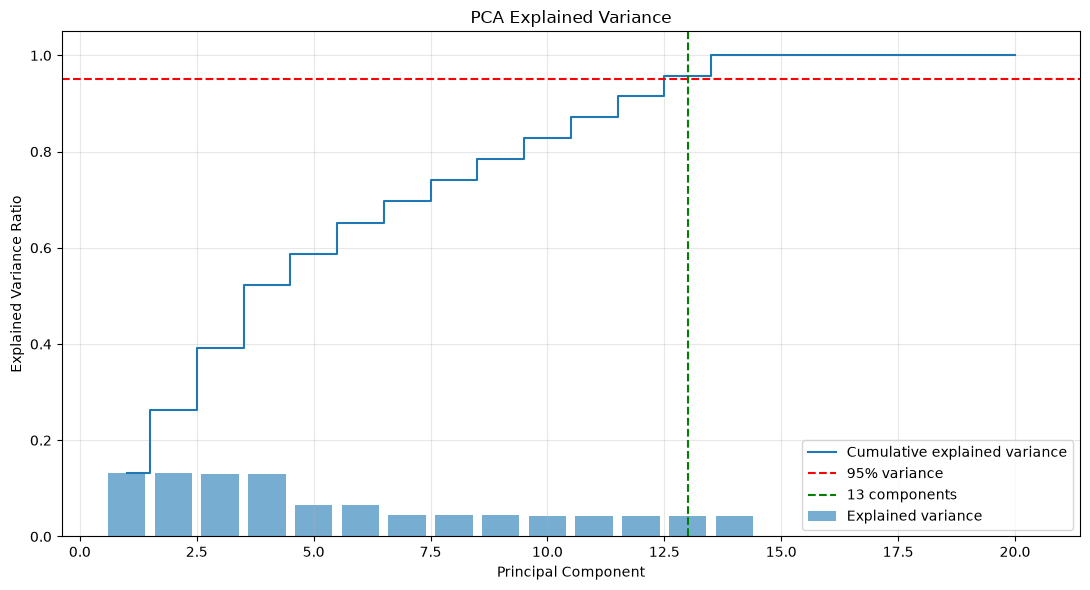

In [7]:
pca_full = PCA()

pca_full.fit(X_train_processed)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

n_components_95 = np.searchsorted(
    cumulative_variance, 0.95
) + 1

print("Початкова кількість ознак:", X_train_processed.shape[1])
print("Кількість компонент для 95% дисперсії:", n_components_95)

plt.figure(figsize=(11, 6))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.6,
    label="Explained variance"
)

plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where="mid",
    label="Cumulative explained variance"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% variance"
)

plt.axvline(
    x=n_components_95,
    color="green",
    linestyle="--",
    label=f"{n_components_95} components"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

features_before = X_train_processed.shape[1]
features_after = X_train_pca.shape[1]

reduction_percent = (
    (features_before - features_after) / features_before
) * 100

print("Кількість ознак до PCA:", features_before)
print("Кількість компонент після PCA:", features_after)
print("Зменшення розмірності:", round(reduction_percent, 2), "%")
print("Збережена дисперсія:", round(
    pca.explained_variance_ratio_.sum() * 100, 2
), "%")

Кількість ознак до PCA: 20
Кількість компонент після PCA: 13
Зменшення розмірності: 35.0 %
Збережена дисперсія: 95.76 %


1.8. Навчання Decision Tree після застосування PCA

In [9]:
dt_after = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

start_time = time.perf_counter()

dt_after.fit(X_train_pca, y_train)

time_after = time.perf_counter() - start_time

y_pred_after = dt_after.predict(X_test_pca)

accuracy_after = accuracy_score(y_test, y_pred_after)
f1_after = f1_score(y_test, y_pred_after, average="macro")

print("Decision Tree після PCA")
print("Accuracy:", round(accuracy_after, 4))
print("F1-macro:", round(f1_after, 4))
print("Час навчання:", round(time_after, 4), "с")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_after,
    target_names=["Missing", "Alert Data"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_after))

Decision Tree після PCA
Accuracy: 0.4948
F1-macro: 0.4547
Час навчання: 0.3441 с

Classification Report:
              precision    recall  f1-score   support

     Missing       0.49      0.22      0.31      6015
  Alert Data       0.50      0.77      0.60      5985

    accuracy                           0.49     12000
   macro avg       0.49      0.50      0.45     12000
weighted avg       0.49      0.49      0.45     12000


Confusion Matrix:
[[1342 4673]
 [1389 4596]]


1.9. Порівняння результатів до та після PCA

        Показник  До PCA  Після PCA
        Accuracy  0.5116     0.4948
        F1-macro  0.5116     0.4547
 Кількість ознак 20.0000    13.0000
Час навчання (с)  0.1481     0.3441


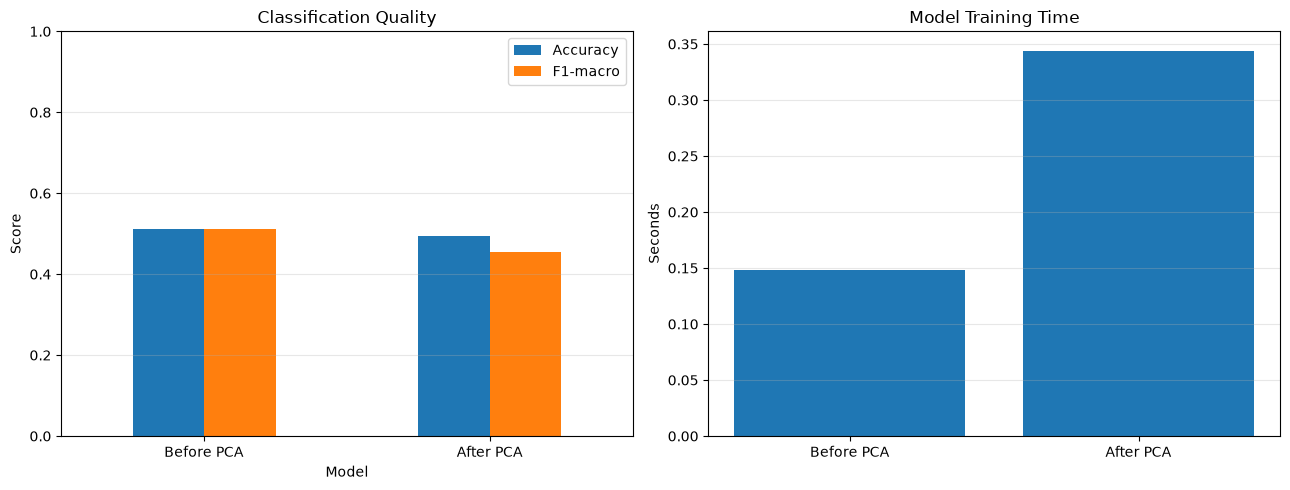

In [10]:
comparison = pd.DataFrame({
    "Показник": [
        "Accuracy",
        "F1-macro",
        "Кількість ознак",
        "Час навчання (с)"
    ],
    "До PCA": [
        accuracy_before,
        f1_before,
        features_before,
        time_before
    ],
    "Після PCA": [
        accuracy_after,
        f1_after,
        features_after,
        time_after
    ]
})

print(comparison.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_comparison = pd.DataFrame({
    "Model": ["Before PCA", "After PCA"],
    "Accuracy": [accuracy_before, accuracy_after],
    "F1-macro": [f1_before, f1_after]
})

metrics_comparison.set_index("Model").plot(
    kind="bar",
    ax=axes[0],
    rot=0
)

axes[0].set_title("Classification Quality")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    ["Before PCA", "After PCA"],
    [time_before, time_after]
)

axes[1].set_title("Model Training Time")
axes[1].set_ylabel("Seconds")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

1.9.1. Порівняння повного часу навчання з урахуванням PCA до та після PCA

In [ ]:


# 1.10. Порівняння повного часу навчання з урахуванням PCA

# 1. Навчання Decision Tree без PCA
model_without_pca = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

start = time.perf_counter()

model_without_pca.fit(X_train_processed, y_train)

time_without_pca = time.perf_counter() - start

pred_without_pca = model_without_pca.predict(X_test_processed)

# 2. PCA + навчання Decision Tree
start = time.perf_counter()

pca_time = PCA(n_components=0.95, random_state=42)
X_train_reduced = pca_time.fit_transform(X_train_processed)

model_with_pca = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

model_with_pca.fit(X_train_reduced, y_train)

time_with_pca_total = time.perf_counter() - start

X_test_reduced = pca_time.transform(X_test_processed)
pred_with_pca = model_with_pca.predict(X_test_reduced)

# 3. Порівняння результатів
time_results = pd.DataFrame({
    "Модель": [
        "Decision Tree",
        "PCA + Decision Tree"
    ],
    "Повний час навчання (с)": [
        time_without_pca,
        time_with_pca_total
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_without_pca),
        accuracy_score(y_test, pred_with_pca)
    ],
    "F1-macro": [
        f1_score(y_test, pred_without_pca, average="macro"),
        f1_score(y_test, pred_with_pca, average="macro")
    ]
})

print("Порівняння повного часу навчання:")
print(time_results.round(4).to_string(index=False))

print(
    "\nРізниця часу:",
    round(time_with_pca_total - time_without_pca, 4),
    "с"
)

if time_with_pca_total < time_without_pca:
    print("Застосування PCA скоротило повний час навчання.")
else:
    print("Застосування PCA не скоротило повний час навчання.")



Порівняння повного часу навчання:
             Модель  Повний час навчання (с)  Accuracy  F1-macro
      Decision Tree                   0.1541    0.5116    0.5116
PCA + Decision Tree                   0.3505    0.4948    0.4547

Різниця часу: 0.1964 с
Застосування PCA не скоротило повний час навчання.


1.10. Автоматичний висновок щодо впливу PCA

In [11]:
accuracy_change = accuracy_after - accuracy_before
f1_change = f1_after - f1_before

print("ВИСНОВКИ ЩОДО PCA\n")

print(
    f"Кількість ознак зменшилася з {features_before} "
    f"до {features_after}, тобто на {reduction_percent:.2f}%."
)

print(
    f"Accuracy змінилася з {accuracy_before:.4f} "
    f"до {accuracy_after:.4f} "
    f"(різниця: {accuracy_change:+.4f})."
)

print(
    f"F1-macro змінився з {f1_before:.4f} "
    f"до {f1_after:.4f} "
    f"(різниця: {f1_change:+.4f})."
)

print(
    f"Час навчання змінився з {time_before:.4f} с "
    f"до {time_after:.4f} с."
)

if time_after < time_before:
    print("Навчання моделі після PCA стало швидшим.")
elif time_after > time_before:
    print("Навчання моделі після PCA стало повільнішим.")
else:
    print("Час навчання практично не змінився.")

if f1_change > 0.01:
    print("PCA покращив якість класифікації за F1-macro.")
elif f1_change < -0.01:
    print("PCA погіршив якість класифікації за F1-macro.")
else:
    print("Якість класифікації за F1-macro змінилася незначно.")

ВИСНОВКИ ЩОДО PCA

Кількість ознак зменшилася з 20 до 13, тобто на 35.00%.
Accuracy змінилася з 0.5116 до 0.4948 (різниця: -0.0167).
F1-macro змінився з 0.5116 до 0.4547 (різниця: -0.0568).
Час навчання змінився з 0.1481 с до 0.3441 с.
Навчання моделі після PCA стало повільнішим.
PCA погіршив якість класифікації за F1-macro.


1.11. Зниження розмірності до 2D за допомогою PCA

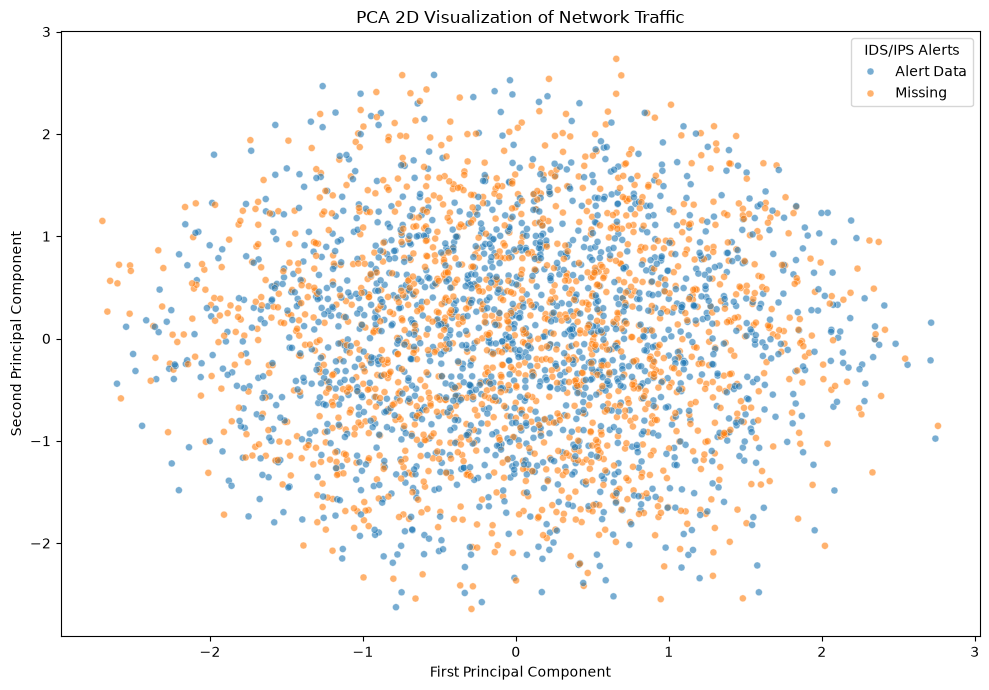

Пояснена дисперсія двох компонент: 26.66 %


,PCA 1,PCA 2,Class
304,-1.297307,-1.530654,Missing
703,-0.917328,0.259723,Alert Data
2741,1.043119,-0.728738,Missing
1414,0.672632,0.241359,Missing
1963,-2.304283,0.688528,Missing


In [12]:
rng = np.random.default_rng(42)

sample_size = min(3000, len(X_train_processed))

sample_indices = rng.choice(
    len(X_train_processed),
    size=sample_size,
    replace=False
)

X_vis = X_train_processed[sample_indices]
y_vis = y_train.iloc[sample_indices].to_numpy()

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_vis)

pca_vis_df = pd.DataFrame({
    "PCA 1": X_pca_2d[:, 0],
    "PCA 2": X_pca_2d[:, 1],
    "Class": np.where(y_vis == 1, "Alert Data", "Missing")
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_vis_df,
    x="PCA 1",
    y="PCA 2",
    hue="Class",
    alpha=0.6,
    s=25
)

# lim = (X_tsne.min() - 2, X_tsne.max() + 2)

# plt.xlim(lim)
# plt.ylim(lim)
# plt.gca().set_aspect("equal")

plt.title("PCA 2D Visualization of Network Traffic")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend(title="IDS/IPS Alerts")
plt.tight_layout()
plt.show()

print(
    "Пояснена дисперсія двох компонент:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

pca_vis_df.sample(5)

1.12. Зниження розмірності за допомогою t-SNE 

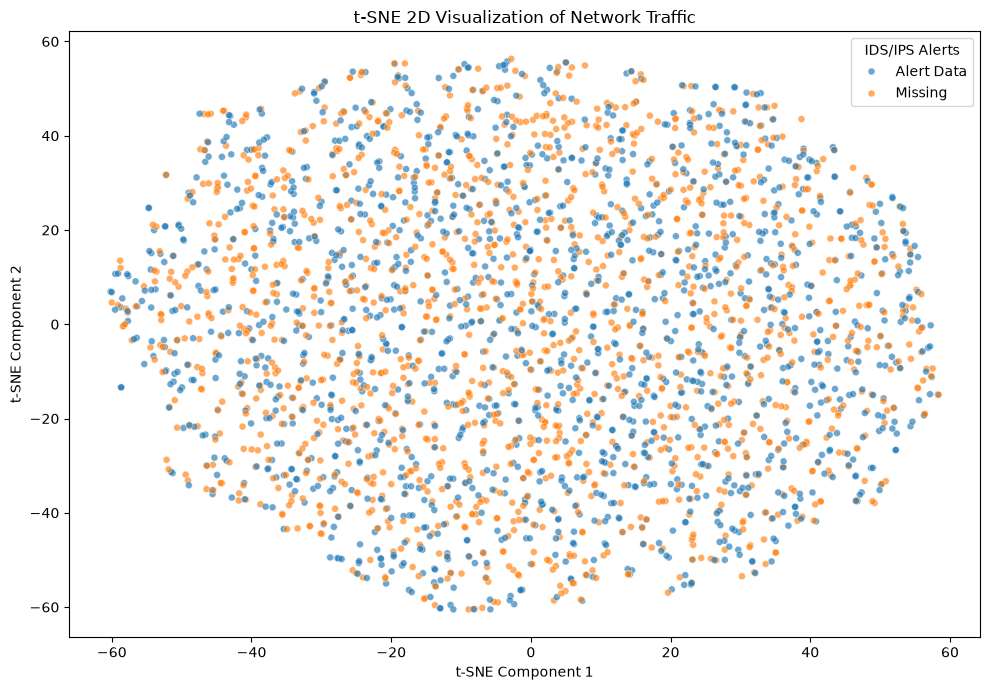

,t-SNE 1,t-SNE 2,Class
1319,27.599043,19.515707,Missing
270,40.363144,-31.121151,Missing
2980,0.656751,-17.700399,Alert Data
252,5.296316,-35.763760,Missing
1971,51.892590,14.381107,Missing


In [13]:
tsne_input_components = min(30, X_vis.shape[1])

pca_for_tsne = PCA(n_components=tsne_input_components)
X_tsne_input = pca_for_tsne.fit_transform(X_vis)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame({
    "t-SNE 1": X_tsne[:, 0],
    "t-SNE 2": X_tsne[:, 1],
    "Class": np.where(y_vis == 1, "Alert Data", "Missing")
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x="t-SNE 1",
    y="t-SNE 2",
    hue="Class",
    alpha=0.65,
    s=25
)

# lim = (X_tsne.min() - 2, X_tsne.max() + 2)

# plt.xlim(lim)
# plt.ylim(lim)
# plt.gca().set_aspect("equal")

plt.title("t-SNE 2D Visualization of Network Traffic")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="IDS/IPS Alerts")
plt.tight_layout()
plt.show()

tsne_df.sample(5)

1.13. Порівняння візуалізацій PCA та t-SNE

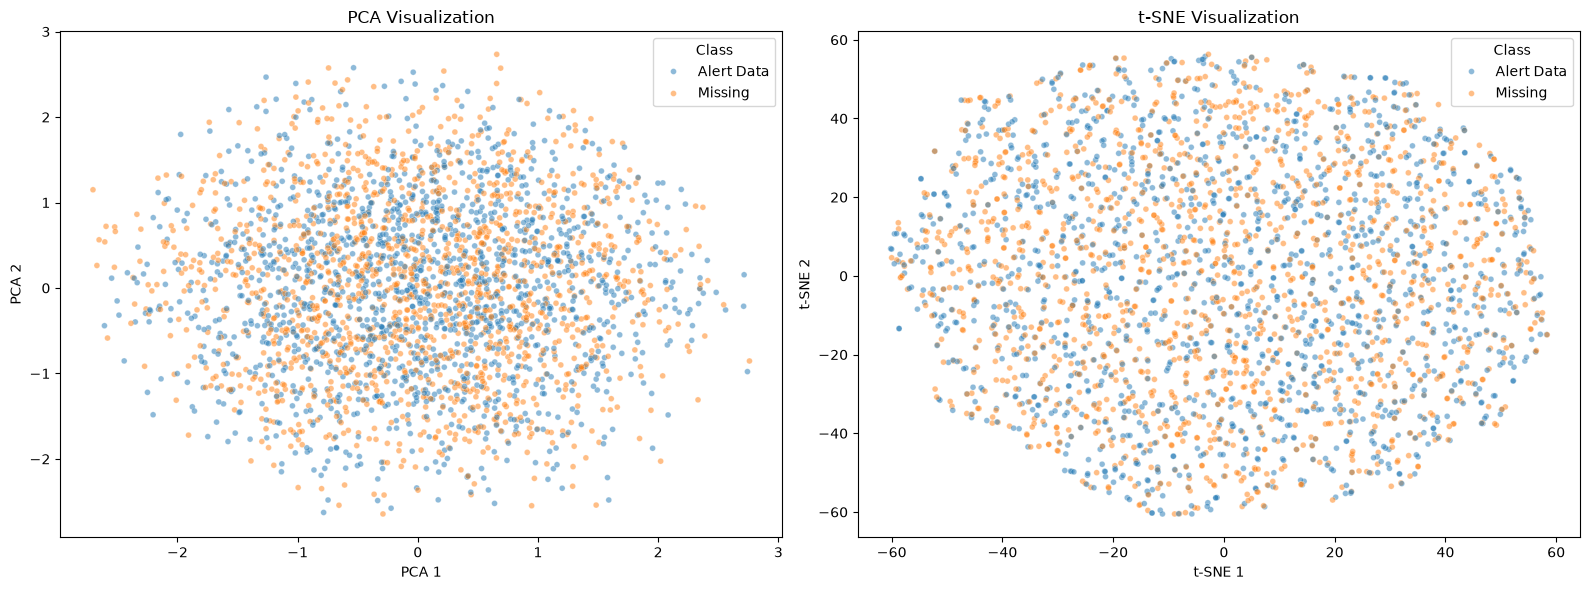

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=pca_vis_df,
    x="PCA 1",
    y="PCA 2",
    hue="Class",
    alpha=0.5,
    s=18,
    ax=axes[0]
)

axes[0].set_title("PCA Visualization")

sns.scatterplot(
    data=tsne_df,
    x="t-SNE 1",
    y="t-SNE 2",
    hue="Class",
    alpha=0.5,
    s=18,
    ax=axes[1]
)

axes[1].set_title("t-SNE Visualization")

plt.tight_layout()
plt.show()

У першій частині лабораторної роботи було досліджено методи зниження розмірності PCA та t-SNE на основі датасету cybersecurity_attacks.csv. Для оцінювання впливу PCA на якість класифікації використано алгоритм Decision Tree.
1. Вплив PCA на якість класифікації. До застосування PCA модель Decision Tree продемонструвала Accuracy = 0,5116 та F1-macro = 0,5116. Після зниження розмірності показники зменшилися до Accuracy = 0,4948 та F1-macro = 0,4547. Отже, застосування PCA призвело до погіршення якості класифікації: Accuracy знизилася на 1,68 відсоткового пункту, а F1-macro — на 5,69 відсоткового пункту. Обидві моделі продемонстрували низьку якість класифікації, близьку до випадкового вгадування для двох збалансованих класів.
2. Зменшення кількості ознак. Після попередньої обробки та кодування дані містили 20 ознак. Застосування PCA дозволило скоротити їх кількість до 13 компонент, тобто зменшити розмірність на 35%. При цьому вдалося зберегти 95,76% поясненої дисперсії. Таким чином, PCA забезпечив зменшення розмірності даних зі збереженням більшої частини їхньої варіації, однак це не призвело до покращення класифікації.
3. Вплив PCA на час навчання. До застосування PCA час навчання Decision Tree становив 0,1643 с, а після — 0,3532 с. Отже, час навчання збільшився приблизно у 2,15 раза. Таким чином, у проведеному експерименті PCA не забезпечив прискорення навчання моделі, незважаючи на зменшення кількості ознак. Водночас ці результати стосуються лише часу навчання класифікатора без урахування обчислення PCA.
4. Результати двовимірної візуалізації PCA. Для візуалізації дані було перетворено у двовимірний простір за допомогою двох головних компонент, які пояснюють 26,66% загальної дисперсії. На графіку спостерігається значне перекриття об'єктів класів Alert Data та Missing, без чітко виражених меж між ними. Це свідчить про відсутність помітного розділення класів у двовимірному представленні PCA.
5. Результати візуалізації t-SNE. Метод t-SNE дозволив отримати двовимірне представлення даних зі збереженням особливостей їхньої локальної структури. На отриманому графіку точки обох класів розташовані впереміш, без чітко відокремлених областей для Alert Data та Missing. Отже, t-SNE також не виявив вираженого розділення об'єктів за цільовими мітками. Це узгоджується з низькими показниками якості класифікації Decision Tree.

**Загальний висновок:** У результаті виконання першої частини лабораторної роботи встановлено, що PCA дозволив зменшити кількість ознак на 35% зі збереженням 95,76% поясненої дисперсії, проте погіршив якість класифікації та збільшив час навчання Decision Tree. Візуалізації PCA і t-SNE показали значне перекриття двох класів, що свідчить про складність їх розділення за використаними ознаками. Отже, у межах проведеного експерименту застосування PCA не покращило ефективність класифікації, а методи PCA та t-SNE виявилися корисними для аналізу структури даних та візуального дослідження розподілу класів.

**Частина 2**. Кластерний аналіз

Завдання: Візьміть датасет з лабораторної роботи №1. Не використовуйте мітки класів (target) під час кластеризації.
Виконайте кластеризацію даних за допомогою алгоритму K-Means.  Визначте доцільну кількість кластерів за допомогою Elbow Method та/або Silhouette Score.  Візуалізуйте отримані кластери у 2D за допомогою PCA або t-SNE. Після виконання кластеризації порівняйте отримані кластери зі справжніми класами датасету.  Зробіть висновок: чи відповідає знайдена кластерна структура реальним класам?
Якщо датасет містить велику кількість класів, для спрощення аналізу можна залишити 2–3 класи, обґрунтувавши свій вибір.
Важливо: кластер і клас — не одне й те саме. Не очікується, що K-Means обов'язково відтворить початкові класи датасету. Потрібно проаналізувати та пояснити отриманий результат.

2.1. Підготовка даних для кластеризації

In [15]:

X_cluster_raw = df[features].copy()

cluster_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numerical_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categorical_features
    )
])

X_cluster_full = cluster_preprocessor.fit_transform(X_cluster_raw)

y_cluster_full = df[target].eq("Alert Data").astype(int).to_numpy()

rng = np.random.default_rng(42)

sample_size_cluster = min(5000, len(X_cluster_full))

sample_indices_cluster = rng.choice(
    len(X_cluster_full),
    size=sample_size_cluster,
    replace=False
)

X_cluster = X_cluster_full[sample_indices_cluster]
y_cluster_true = y_cluster_full[sample_indices_cluster]

print("Розмір даних для кластеризації:", X_cluster.shape)
print("Кількість ознак:", X_cluster.shape[1])
print("Кількість об'єктів:", len(X_cluster))


Розмір даних для кластеризації: (5000, 20)
Кількість ознак: 20
Кількість об'єктів: 5000


2.2. Визначення кількості кластерів за допомогою Elbow Method

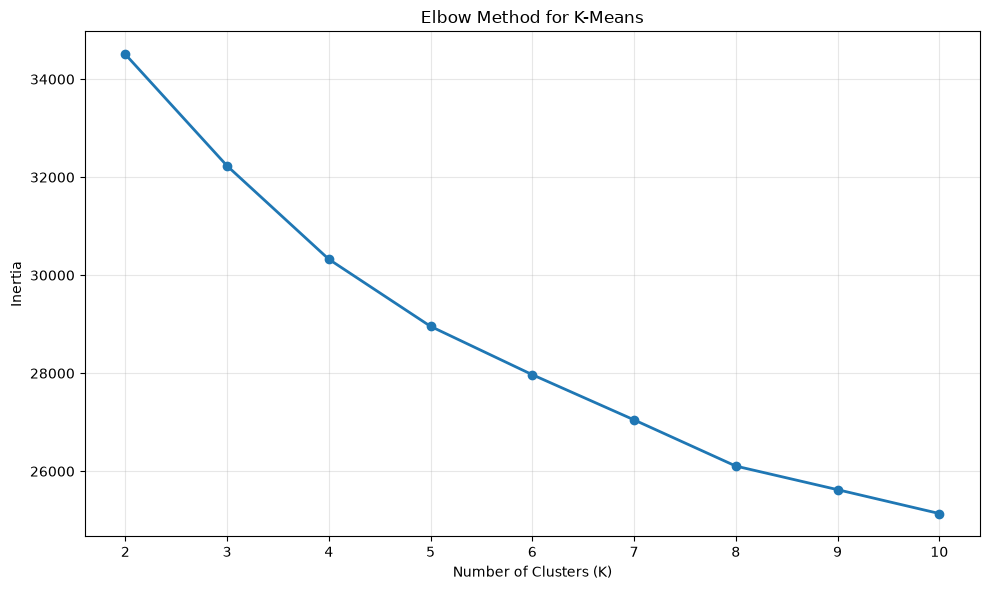

In [16]:
k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)

    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2
)


# elbow_results = pd.DataFrame({
#     "Кількість кластерів (K)": list(k_values),
#     "Inertia": inertia_values
# })

# print("Результати Elbow Method:")
# display(elbow_results.round(4))


plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.3. Визначення кількості кластерів за допомогою Silhouette Score

 K    Inertia  Silhouette Score
 2 34507.0987            0.0956
 3 32231.0868            0.0847
 4 30325.7106            0.0831
 5 28956.2819            0.0849
 6 27969.7459            0.0794
 7 27048.2520            0.0840
 8 26105.4262            0.0838
 9 25623.9968            0.0757
10 25137.0515            0.0736


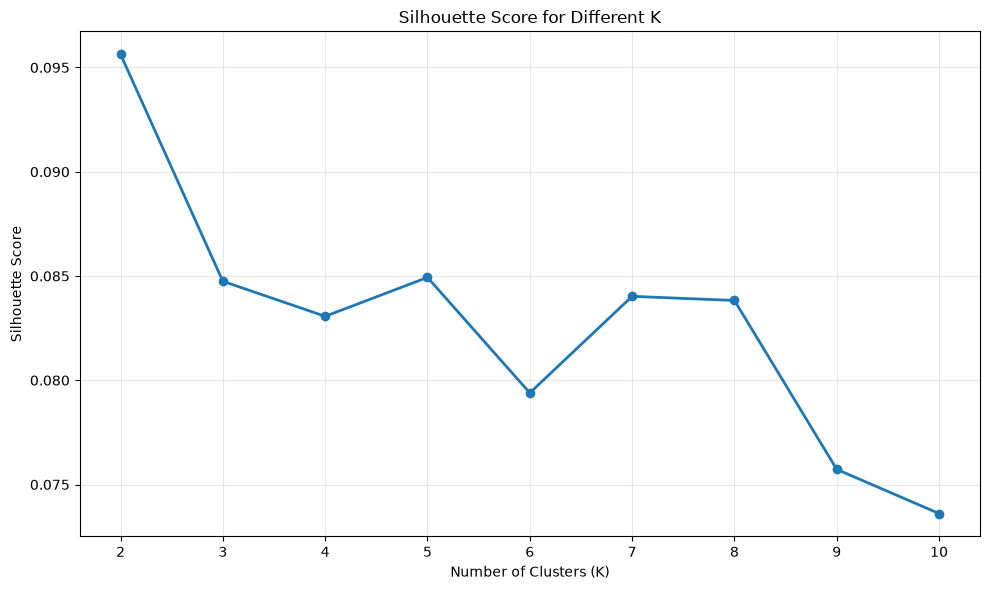

In [17]:
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        cluster_labels,
        sample_size=min(2000, len(X_cluster)),
        random_state=42
    )

    silhouette_values.append(score)

silhouette_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print(silhouette_results.round(4).to_string(index=False))

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o",
    linewidth=2
)

plt.title("Silhouette Score for Different K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.4. Вибір доцільної кількості кластерів

In [18]:
optimal_k = list(k_values)[np.argmax(silhouette_values)]

best_silhouette = max(silhouette_values)

print("Оптимальна кількість кластерів:", optimal_k)
print("Найкращий Silhouette Score:", round(best_silhouette, 4))

Оптимальна кількість кластерів: 2
Найкращий Silhouette Score: 0.0956


2.5. Кластеризація даних за допомогою K-Means

In [19]:
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels_final = kmeans_final.fit_predict(X_cluster)

print("Кількість кластерів:", optimal_k)

print("\nРозподіл об'єктів за кластерами:")
print(
    pd.Series(cluster_labels_final)
    .value_counts()
    .sort_index()
)

print("\nInertia:", round(kmeans_final.inertia_, 4))

Кількість кластерів: 2

Розподіл об'єктів за кластерами:
0    2512
1    2488
Name: count, dtype: int64

Inertia: 34507.0987


2.6. Візуалізація отриманих кластерів у 2D за допомогою PCA

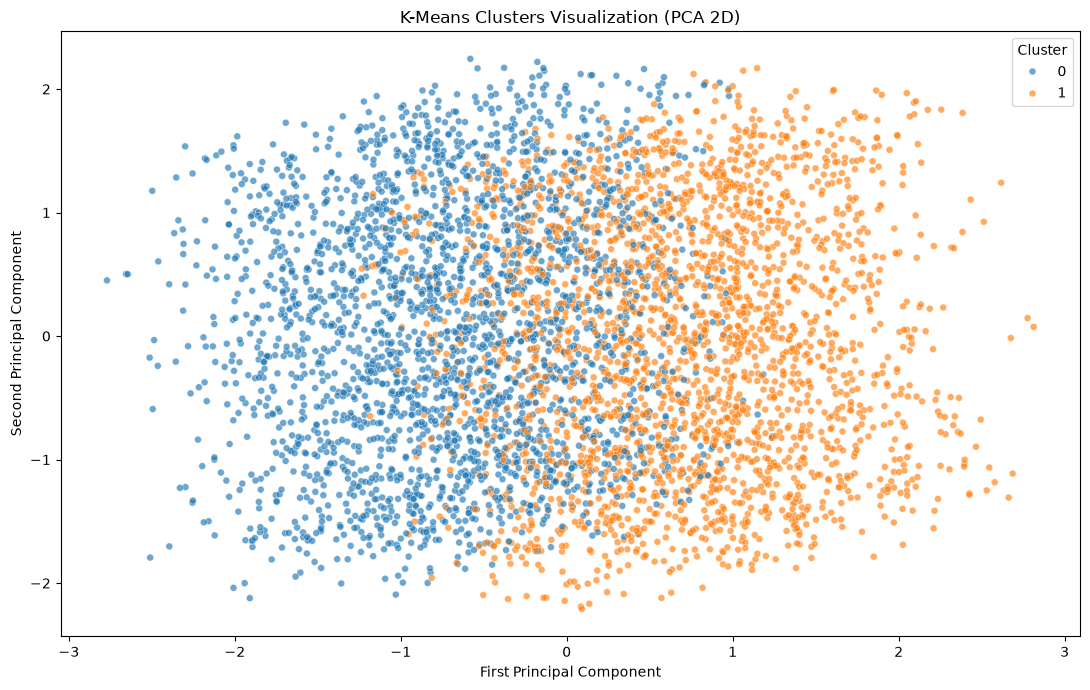

Пояснена дисперсія двох компонент: 26.68 %


In [20]:
pca_cluster = PCA(n_components=2)

X_cluster_2d = pca_cluster.fit_transform(X_cluster)

cluster_df = pd.DataFrame({
    "PCA 1": X_cluster_2d[:, 0],
    "PCA 2": X_cluster_2d[:, 1],
    "Cluster": cluster_labels_final.astype(str)
})

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=cluster_df,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=25
)

plt.title("K-Means Clusters Visualization (PCA 2D)")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Пояснена дисперсія двох компонент:",
    round(
        pca_cluster.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

2.7. Візуалізація справжніх класів у тому самому просторі PCA

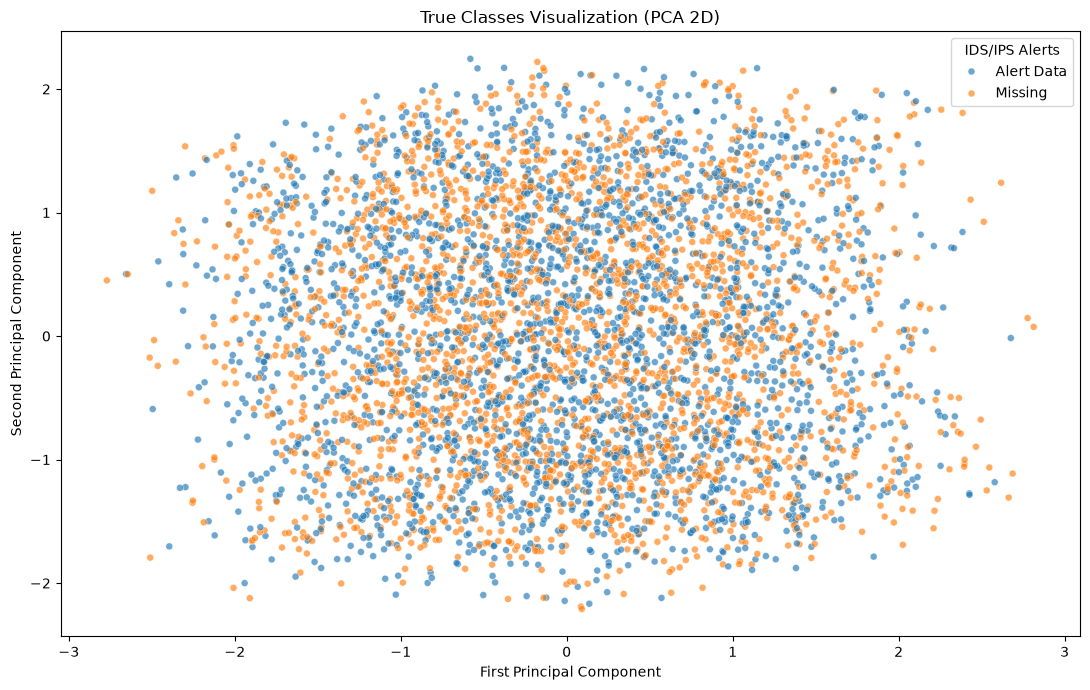

In [21]:
true_class_df = pd.DataFrame({
    "PCA 1": X_cluster_2d[:, 0],
    "PCA 2": X_cluster_2d[:, 1],
    "Class": np.where(
        y_cluster_true == 1,
        "Alert Data",
        "Missing"
    )
})

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=true_class_df,
    x="PCA 1",
    y="PCA 2",
    hue="Class",
    alpha=0.65,
    s=25
)

plt.title("True Classes Visualization (PCA 2D)")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend(title="IDS/IPS Alerts")
plt.tight_layout()
plt.show()

2.8. Порівняння кластерів і справжніх класів

Кількість об'єктів кожного класу в кластерах:
True Class  Alert Data  Missing
Cluster                        
0                 1246     1266
1                 1222     1266

Відсотковий розподіл класів у кластерах:
True Class  Alert Data  Missing
Cluster                        
0                49.60    50.40
1                49.12    50.88


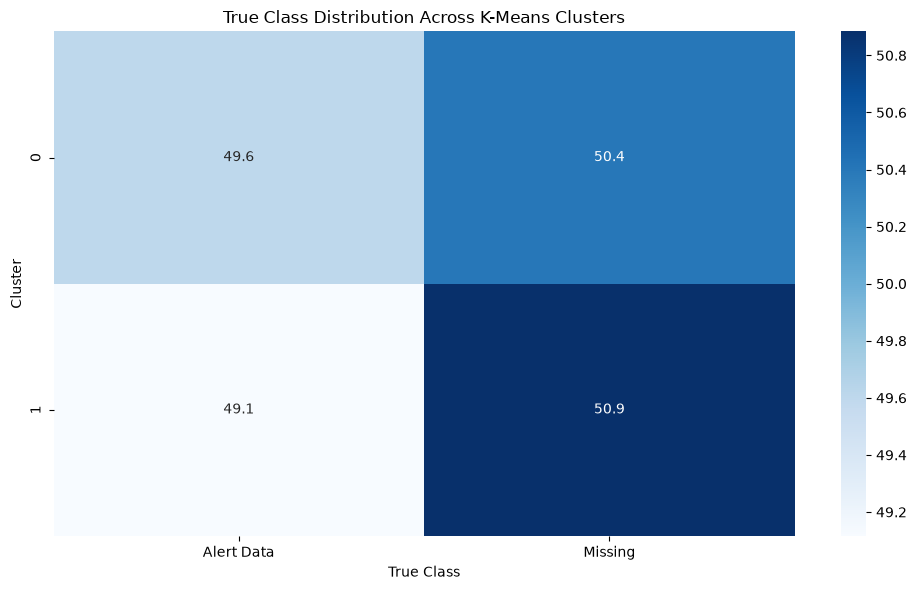

In [22]:
comparison_df = pd.DataFrame({
    "Cluster": cluster_labels_final,
    "True Class": np.where(
        y_cluster_true == 1,
        "Alert Data",
        "Missing"
    )
})

cluster_class_table = pd.crosstab(
    comparison_df["Cluster"],
    comparison_df["True Class"]
)

print("Кількість об'єктів кожного класу в кластерах:")
print(cluster_class_table)

cluster_class_percent = pd.crosstab(
    comparison_df["Cluster"],
    comparison_df["True Class"],
    normalize="index"
) * 100

print("\nВідсотковий розподіл класів у кластерах:")
print(cluster_class_percent.round(2))

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_class_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("True Class Distribution Across K-Means Clusters")
plt.xlabel("True Class")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

2.9. Кількісне оцінювання відповідності кластерів класам

In [23]:
ari_score = adjusted_rand_score(
    y_cluster_true,
    cluster_labels_final
)

nmi_score = normalized_mutual_info_score(
    y_cluster_true,
    cluster_labels_final
)

ami_score = adjusted_mutual_info_score(
    y_cluster_true,
    cluster_labels_final
)

print("Adjusted Rand Index (ARI):", round(ari_score, 4))
print("Normalized Mutual Information (NMI):", round(nmi_score, 4))
print("Adjusted Mutual Information (AMI):", round(ami_score, 4))

Adjusted Rand Index (ARI): -0.0002
Normalized Mutual Information (NMI): 0.0
Adjusted Mutual Information (AMI): -0.0001


2.10. Порівняння кластерів і класів на спільних графіках

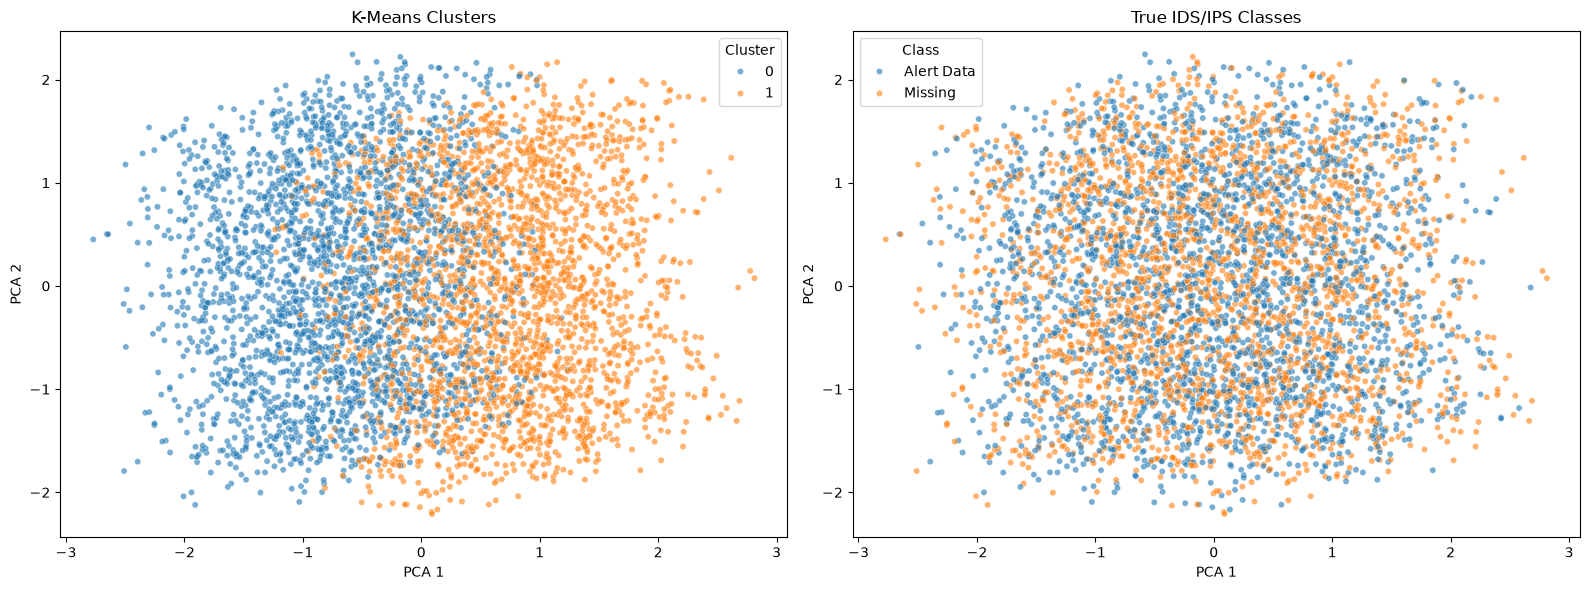

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=cluster_df,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette="tab10",
    alpha=0.6,
    s=20,
    ax=axes[0]
)

axes[0].set_title("K-Means Clusters")

sns.scatterplot(
    data=true_class_df,
    x="PCA 1",
    y="PCA 2",
    hue="Class",
    alpha=0.6,
    s=20,
    ax=axes[1]
)

axes[1].set_title("True IDS/IPS Classes")

plt.tight_layout()
plt.show()

2.11. Автоматичний аналіз результатів кластеризації

In [25]:
print("РЕЗУЛЬТАТИ КЛАСТЕРНОГО АНАЛІЗУ\n")

print("Кількість об'єктів:", len(X_cluster))
print("Кількість ознак:", X_cluster.shape[1])
print("Обрана кількість кластерів:", optimal_k)

print(
    "Silhouette Score:",
    round(best_silhouette, 4)
)

print(
    "Adjusted Rand Index:",
    round(ari_score, 4)
)

print(
    "Normalized Mutual Information:",
    round(nmi_score, 4)
)

print(
    "Adjusted Mutual Information:",
    round(ami_score, 4)
)

print("\nВідповідність кластерів справжнім класам:")

if ari_score < 0.1 and ami_score < 0.1:
    print(
        "Знайдена кластерна структура має слабку "
        "відповідність справжнім класам."
    )
elif ari_score < 0.5:
    print(
        "Спостерігається часткова відповідність "
        "кластерів справжнім класам."
    )
else:
    print(
        "Спостерігається помітна відповідність "
        "кластерів справжнім класам."
    )

РЕЗУЛЬТАТИ КЛАСТЕРНОГО АНАЛІЗУ

Кількість об'єктів: 5000
Кількість ознак: 20
Обрана кількість кластерів: 2
Silhouette Score: 0.0956
Adjusted Rand Index: -0.0002
Normalized Mutual Information: 0.0
Adjusted Mutual Information: -0.0001

Відповідність кластерів справжнім класам:
Знайдена кластерна структура має слабку відповідність справжнім класам.


У другій частині лабораторної роботи було виконано кластерний аналіз датасету cybersecurity_attacks.csv за допомогою алгоритму K-Means. Для дослідження використано 5000 об'єктів, представлених 20 ознаками після попередньої обробки та кодування. Кластеризацію проведено без використання міток цільової змінної IDS/IPS Alerts, які застосовувалися лише для подальшого порівняння отриманих кластерів зі справжніми класами.
1. Визначення доцільної кількості кластерів. Для визначення кількості кластерів використано Elbow Method та Silhouette Score. Метод ліктя показав поступове зменшення Inertia від 34507,0987 при K = 2 до 25137,0515 при K = 10, проте чітко вираженої точки перегину не виявлено. Найбільше значення Silhouette Score становило 0,0956 при K = 2. Тому серед перевірених варіантів для подальшого аналізу обрано два кластери. Водночас низьке значення Silhouette Score свідчить про слабку відокремленість сформованих груп.
2. Результати кластеризації та візуалізації. Алгоритм K-Means розподілив 5000 об'єктів на два кластери: кластер 0 містить 2512 об'єктів (50,24%), а кластер 1 — 2488 об'єктів (49,76%). Значення Inertia становило 34507,0987. Для двовимірної візуалізації результатів використано метод PCA. Дві головні компоненти пояснюють 26,68% загальної дисперсії. На графіку K-Means спостерігається часткове просторове розділення кластерів переважно вздовж першої головної компоненти, однак їхні області значно перекриваються. Водночас на графіку справжніх класів об'єкти Alert Data та Missing розташовані впереміш без чітко виражених меж.
3. Порівняння отриманих кластерів зі справжніми класами датасету. Чи відповідає знайдена кластерна структура реальним класам?

Після виконання кластеризації проведено порівняння отриманих кластерів зі справжніми класами датасету. У кластері 0 міститься 1246 об'єктів класу Alert Data (49,60%) та 1266 об'єктів класу Missing (50,40%). У кластері 1 міститься 1222 об'єкти класу Alert Data (49,12%) та 1266 об'єктів класу Missing (50,88%). Отже, обидва кластери мають майже однаковий розподіл початкових класів. Різниця між частками Alert Data у двох кластерах становить лише 0,48 відсоткового пункту.
Для кількісного оцінювання відповідності обчислено метрики ARI = −0,0002, NMI = 0,0000 та AMI = −0,0001. Значення всіх трьох показників близькі до нуля, що підтверджує практичну відсутність узгодженості між отриманими кластерами та справжніми класами. Таким чином, знайдена кластерна структура практично не відповідає початковому поділу датасету на класи Alert Data та Missing.

4. Обґрунтування вибору кількості класів для аналізу.

У досліджуваному датасеті для цільової змінної IDS/IPS Alerts використовуються дві категорії: Alert Data та Missing. Категорія Alert Data означає наявність відповідного запису про спрацювання IDS/IPS, а Missing — відсутність значення в цьому полі, що не обов'язково свідчить про відсутність кібератаки. Оскільки кількість категорій уже становить дві, додаткове скорочення кількості класів не потрібне. Це дозволило порівняти результати кластеризації з початковими мітками без вилучення будь-якої категорії.

5. Пояснення отриманих результатів. Чому кластери не збігаються з початковими класами?

Кластер і клас є різними поняттями. Клас — це заздалегідь визначена категорія об'єктів, тоді як кластер — група об'єктів, сформована алгоритмом на основі подібності їхніх ознак. Алгоритм K-Means належить до методів навчання без учителя та не використовує справжні мітки класів під час кластеризації, тому не зобов'язаний відтворювати початковий поділ датасету.
У результаті дослідження K-Means сформував два кластери, однак кожен із них містить приблизно однакові частки об'єктів обох початкових класів. Низький Silhouette Score (0,0956) свідчить про слабку відокремленість кластерів, а значення ARI, NMI та AMI, близькі до нуля, підтверджують практичну відсутність відповідності справжнім класам. На PCA-візуалізації також спостерігається значне перекриття об'єктів класів Alert Data та Missing.
Отже, алгоритм K-Means виявив певне групування об'єктів за подібністю ознак, проте воно практично не пов'язане з початковими класами датасету. Це не є помилкою алгоритму, а демонструє принципову відмінність між кластеризацією та класифікацією.

**Загальний висновок:** У результаті виконання другої частини лабораторної роботи проведено кластерний аналіз 5000 об'єктів датасету cybersecurity_attacks.csv за допомогою K-Means. На основі Elbow Method та Silhouette Score серед перевірених варіантів обрано два кластери, проте їхня відокремленість виявилася слабкою. Порівняння зі справжніми класами показало, що обидва кластери містять майже однакові частки об'єктів категорій Alert Data та Missing. Значення ARI = −0,0002, NMI = 0,0000 та AMI = −0,0001 підтверджують, що знайдена кластерна структура практично не відповідає початковим класам датасету. Таким чином, K-Means сформував групи за подібністю ознак, але не відтворив початковий поділ об'єктів. Отримані результати підтверджують, що кластер і клас є різними поняттями, а алгоритми навчання без учителя не обов'язково формують групи, які збігаються із заздалегідь визначеними категоріями.

**Частина 3**. Обробка та класифікація текстових даних

Завдання: Завантажте набір текстових даних з мітками класів. Проведіть передобробку текстів (наприклад, видалення стоп-слів та пунктуації). За допомогою WordCloud візуалізуйте найбільш характерні слова/словосполучення для кожного класу та поясніть отримані результати. Векторизуйте тексти, наприклад за допомогою `sklearn.feature_extraction.text.TfidfVectorizer`.
Навчіть модель класифікації текстів та оцініть якість класифікації за відповідними метриками.

3.1. Завантаження та початковий аналіз датасету

In [26]:

df_text = pd.read_csv("spam.csv", encoding="latin-1")

df_text = df_text[["v1", "v2"]].rename(
    columns={"v1": "label", "v2": "text"}
)

print("Розмір датасету:", df_text.shape)
print("\nПерші 5 записів:")
display(df_text.head())

print("\nІнформація про датасет:")
df_text.info()


Розмір датасету: (5572, 2)

Перші 5 записів:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Інформація про датасет:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5572 non-null   str  
 1   text    5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


3.2. Перевірка пропусків, дублікатів і розподілу класів

Пропущені значення:


,Missing Values
label,0
text,0


Кількість дублікатів: 403

Розмір після очищення: (5169, 2)


,Кількість,Частка (%)
label,,
ham,4516,87.37
spam,653,12.63


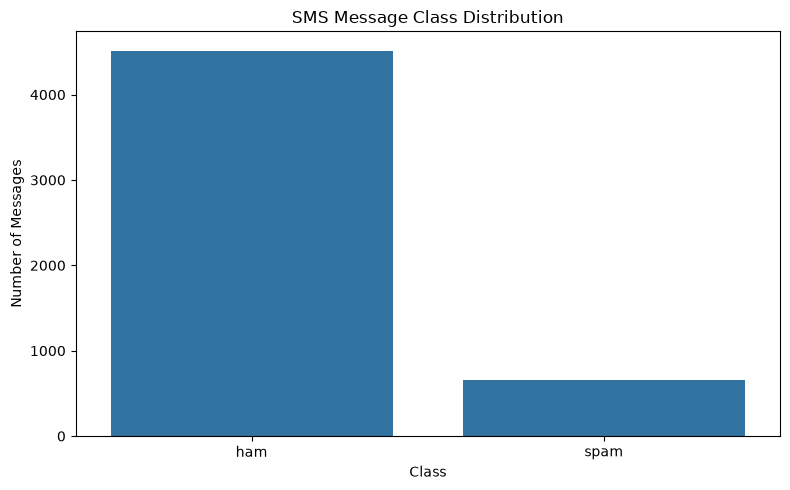

In [27]:

print("Пропущені значення:")
display(df_text.isna().sum().to_frame("Missing Values"))

print("Кількість дублікатів:", df_text.duplicated().sum())

df_text = df_text.dropna(subset=["label", "text"])
df_text = df_text.drop_duplicates().reset_index(drop=True)

print("\nРозмір після очищення:", df_text.shape)

class_distribution = pd.DataFrame({
    "Кількість": df_text["label"].value_counts(),
    "Частка (%)": df_text["label"].value_counts(normalize=True) * 100
})

display(class_distribution.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_text,
    x="label",
    order=["ham", "spam"]
)
plt.title("SMS Message Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


3.3. Попередня обробка текстових даних

In [28]:

stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    words = [
        word for word in text.split()
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(words)

df_text["clean_text"] = df_text["text"].apply(clean_text)

df_text = df_text[
    df_text["clean_text"].str.len() > 0
].reset_index(drop=True)

print("Приклади текстів до та після очищення:")

display(
    df_text[["label", "text", "clean_text"]].head(10)
)


Приклади текстів до та після очищення:


,label,text,clean_text
0,ham,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,dun say early hor say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah don think goes usf lives
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling week word like fun tb ok x...
6,ham,Even my brother is not like to speak with me. ...,brother like speak treat like aids patent
7,ham,As per your request 'Melle Melle (Oru Minnamin...,request melle melle oru minnaminunginte nurung...
8,spam,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,spam,Had your mobile 11 months or more? U R entitle...,mobile months entitled update latest colour mo...


3.4. Візуалізація WordCloud для кожного класу

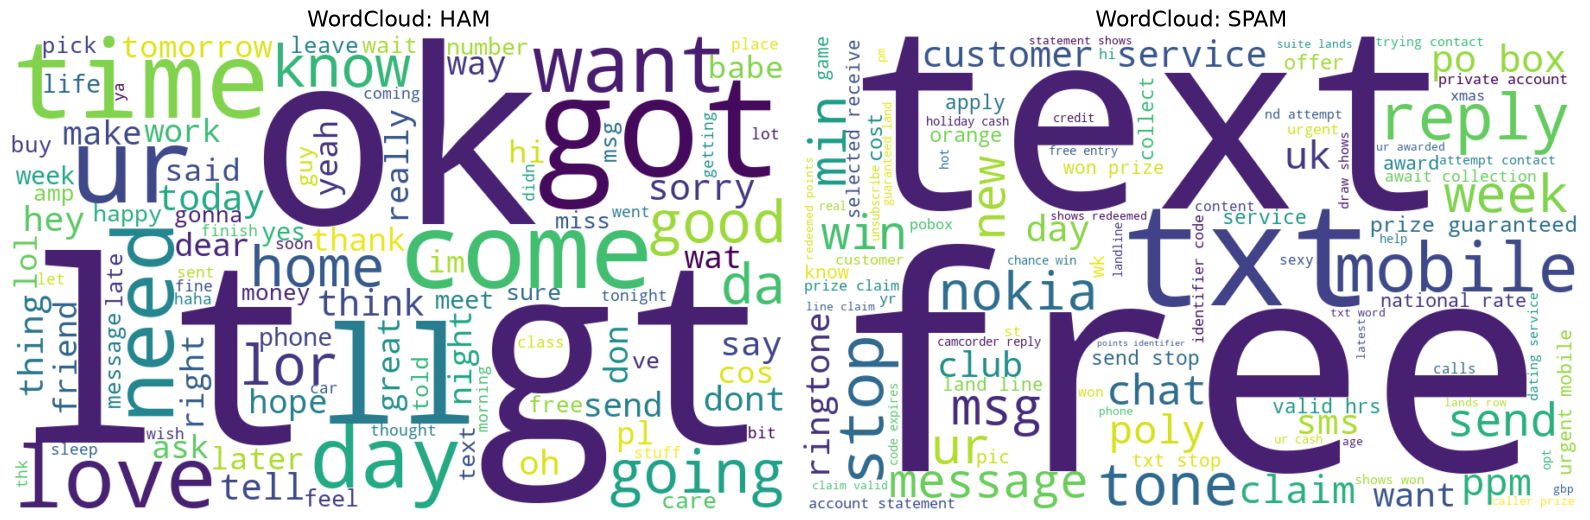

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, label in zip(axes, ["ham", "spam"]):
    class_text = " ".join(
        df_text.loc[
            df_text["label"] == label,
            "clean_text"
        ]
    )

    wordcloud = WordCloud(
        width=900,
        height=550,
        background_color="white",
        collocations=True,
        max_words=100,
        random_state=42
    ).generate(class_text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(f"WordCloud: {label.upper()}", fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()


3.5. Аналіз найбільш характерних слів і словосполучень

In [30]:

from sklearn.feature_extraction.text import CountVectorizer

characteristic_vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000
)

X_terms = characteristic_vectorizer.fit_transform(
    df_text["clean_text"]
)

terms = characteristic_vectorizer.get_feature_names_out()

class_means = {}

for label in ["ham", "spam"]:
    mask = (df_text["label"] == label).to_numpy()
    class_means[label] = np.asarray(
        X_terms[mask].astype(bool).mean(axis=0)
    ).ravel()

for label, other_label in [("ham", "spam"), ("spam", "ham")]:
    difference = class_means[label] - class_means[other_label]
    top_indices = np.argsort(difference)[-15:][::-1]

    result = pd.DataFrame({
        "Слово / словосполучення": terms[top_indices],
        "Різниця частки повідомлень": difference[top_indices]
    })

    print(f"\nХарактерні слова для класу {label.upper()}:")
    display(result.round(4))



Характерні слова для класу HAM:


,Слово / словосполучення,Різниця частки повідомлень
0,lt,0.0499
1,gt,0.0499
2,ok,0.0471
3,lt gt,0.0438
4,ll,0.0428
5,come,0.0415
6,got,0.0389
7,lor,0.0316
8,home,0.0312
9,going,0.0306



Характерні слова для класу SPAM:


,Слово / словосполучення,Різниця частки повідомлень
0,free,0.2175
1,txt,0.1916
2,mobile,0.1502
3,claim,0.1409
4,stop,0.1335
5,text,0.1262
6,reply,0.1226
7,prize,0.1118
8,ur,0.1066
9,won,0.0892


3.6. Розділення даних на навчальну та тестову вибірки

In [31]:

X_text = df_text["clean_text"]
y_text = df_text["label"]

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text,
    y_text,
    test_size=0.2,
    random_state=42,
    stratify=y_text
)

print("Навчальна вибірка:", len(X_train_text))
print("Тестова вибірка:", len(X_test_text))

print("\nРозподіл класів у навчальній вибірці:")
display(y_train_text.value_counts(normalize=True).round(4))

print("\nРозподіл класів у тестовій вибірці:")
display(y_test_text.value_counts(normalize=True).round(4))


Навчальна вибірка: 4116
Тестова вибірка: 1030

Розподіл класів у навчальній вибірці:


label
ham     0.8732
spam    0.1268
Name: proportion, dtype: float64


Розподіл класів у тестовій вибірці:


label
ham     0.8728
spam    0.1272
Name: proportion, dtype: float64

3.7. Векторизація текстів за допомогою TF-IDF

In [32]:

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Розмір навчальної матриці:", X_train_tfidf.shape)
print("Розмір тестової матриці:", X_test_tfidf.shape)

print("Кількість TF-IDF ознак:", len(tfidf.get_feature_names_out()))

display(
    pd.DataFrame({
        "TF-IDF Feature": tfidf.get_feature_names_out()[:20]
    })
)


Розмір навчальної матриці: (4116, 5000)
Розмір тестової матриці: (1030, 5000)
Кількість TF-IDF ознак: 5000


,TF-IDF Feature
0,aah
1,abi
2,abiola
3,abj
4,able
5,abt
6,abt tht
7,aburo
8,aburo enjoy
9,ac


3.8. Підбір оптимальної кількості сусідів для kNN

In [33]:

spam_f1 = make_scorer(
    f1_score,
    pos_label="spam"
)

knn_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("knn", KNeighborsClassifier(
        metric="cosine",
        algorithm="brute"
    ))
])

param_grid = {
    "knn__n_neighbors": list(range(1, 20, 2)),
    "knn__weights": ["uniform", "distance"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring=spam_f1,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_knn.fit(X_train_text, y_train_text)

print("Найкращі параметри:", grid_knn.best_params_)
print("Найкращий F1 для spam (CV):", round(grid_knn.best_score_, 4))


Найкращі параметри: {'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Найкращий F1 для spam (CV): 0.86


3.9. Навчання фінальної моделі та оцінювання якості

In [34]:

best_knn = grid_knn.best_estimator_

y_pred_text = best_knn.predict(X_test_text)

accuracy_text = accuracy_score(y_test_text, y_pred_text)

precision_text = precision_score(
    y_test_text,
    y_pred_text,
    pos_label="spam",
    zero_division=0
)

recall_text = recall_score(
    y_test_text,
    y_pred_text,
    pos_label="spam",
    zero_division=0
)

f1_text = f1_score(
    y_test_text,
    y_pred_text,
    pos_label="spam",
    zero_division=0
)

f1_macro_text = f1_score(
    y_test_text,
    y_pred_text,
    average="macro",
    zero_division=0
)

metrics_text = pd.DataFrame({
    "Метрика": [
        "Accuracy",
        "Precision (spam)",
        "Recall (spam)",
        "F1-score (spam)",
        "F1-macro"
    ],
    "Значення": [
        accuracy_text,
        precision_text,
        recall_text,
        f1_text,
        f1_macro_text
    ]
})

display(metrics_text.round(4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_text,
        y_pred_text,
        labels=["ham", "spam"],
        zero_division=0
    )
)


,Метрика,Значення
0,Accuracy,0.9757
1,Precision (spam),0.9732
2,Recall (spam),0.8321
3,F1-score (spam),0.8971
4,F1-macro,0.9417



Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       899
        spam       0.97      0.83      0.90       131

    accuracy                           0.98      1030
   macro avg       0.97      0.91      0.94      1030
weighted avg       0.98      0.98      0.97      1030



3.10. Побудова матриці помилок

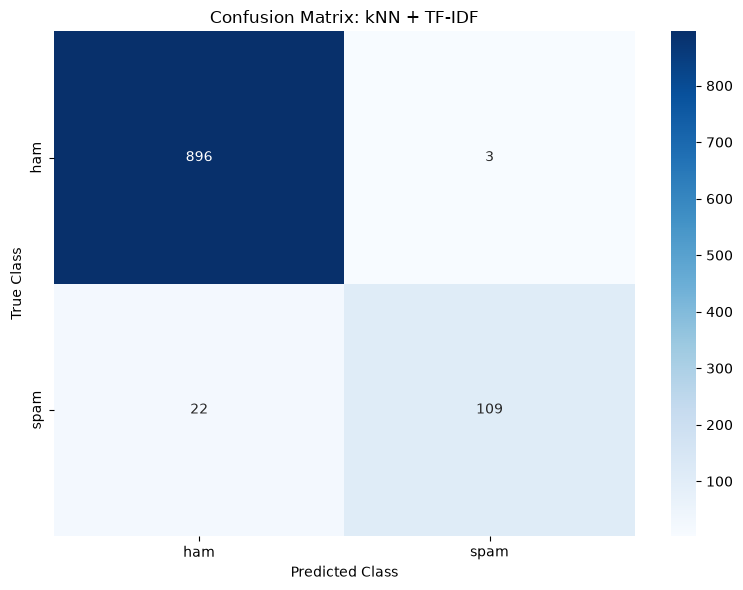

Правильно визначено ham: 896
Ham помилково визначено як spam: 3
Spam помилково визначено як ham: 22
Правильно визначено spam: 109


In [35]:

cm_text = confusion_matrix(
    y_test_text,
    y_pred_text,
    labels=["ham", "spam"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_text,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Confusion Matrix: kNN + TF-IDF")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_text.ravel()

print("Правильно визначено ham:", tn)
print("Ham помилково визначено як spam:", fp)
print("Spam помилково визначено як ham:", fn)
print("Правильно визначено spam:", tp)


3.11. Автоматичний підсумковий аналіз

In [36]:

print("РЕЗУЛЬТАТИ КЛАСИФІКАЦІЇ ТЕКСТОВИХ ДАНИХ\n")

print("Датасет: SMS Spam Collection")
print("Кількість повідомлень:", len(df_text))
print("Класи: ham, spam")
print("Векторизація: TF-IDF")
print("Модель: kNN")

print("\nНайкращі параметри:", grid_knn.best_params_)

print("\nМетрики тестової вибірки:")
print("Accuracy:", round(accuracy_text, 4))
print("Precision (spam):", round(precision_text, 4))
print("Recall (spam):", round(recall_text, 4))
print("F1-score (spam):", round(f1_text, 4))
print("F1-macro:", round(f1_macro_text, 4))

print("\nМатриця помилок:")
print("Правильно визначено ham:", tn)
print("Помилково заблоковано ham:", fp)
print("Пропущено spam:", fn)
print("Правильно визначено spam:", tp)


РЕЗУЛЬТАТИ КЛАСИФІКАЦІЇ ТЕКСТОВИХ ДАНИХ

Датасет: SMS Spam Collection
Кількість повідомлень: 5146
Класи: ham, spam
Векторизація: TF-IDF
Модель: kNN

Найкращі параметри: {'knn__n_neighbors': 3, 'knn__weights': 'distance'}

Метрики тестової вибірки:
Accuracy: 0.9757
Precision (spam): 0.9732
Recall (spam): 0.8321
F1-score (spam): 0.8971
F1-macro: 0.9417

Матриця помилок:
Правильно визначено ham: 896
Помилково заблоковано ham: 3
Пропущено spam: 22
Правильно визначено spam: 109


У третій частині лабораторної роботи було виконано обробку та класифікацію текстових даних на основі датасету SMS Spam Collection (spam.csv). Для дослідження використано SMS-повідомлення англійською мовою, розподілені на два класи: ham — звичайні повідомлення та spam — небажані рекламні або шахрайські повідомлення. Проведено попередню обробку текстів, візуалізацію характерних слів за допомогою WordCloud, векторизацію TF-IDF та класифікацію алгоритмом kNN.
1. Завантаження та аналіз текстового датасету. Початковий датасет містив 5572 повідомлення та два стовпці: label — мітка класу та text — текст повідомлення. Під час перевірки встановлено, що пропущені значення відсутні, проте виявлено 403 дублікати, які було видалено. Після видалення дублікатів залишилося 5169 повідомлень, із яких 4516 (87,37%) належать до класу ham, а 653 (12,63%) — до класу spam. Отже, датасет є незбалансованим, оскільки звичайні повідомлення значно переважають над спамом. Це необхідно враховувати під час оцінювання якості класифікації.
2. Попередня обробка текстових даних. Для підготовки повідомлень до аналізу виконано перетворення текстів до нижнього регістру, видалення пунктуації, цифр, URL-адрес, електронних адрес, англійських стоп-слів та зайвих пробілів. Також вилучено слова довжиною один символ і повідомлення, які після очищення залишилися порожніми. У результаті кількість повідомлень зменшилася з 5169 до 5146. Проведена обробка дозволила зменшити кількість неінформативних елементів і підготувати тексти до подальшої векторизації та класифікації.
3. Візуалізація характерних слів і словосполучень за допомогою WordCloud. Для кожного класу побудовано окрему хмару слів, яка відображає найбільш уживані слова в повідомленнях.
У класі ham переважають слова ok, got, time, come, love, good, home, going, know, day та want. Вони переважно пов'язані з повсякденним спілкуванням, особистими повідомленнями, планами, зустрічами та емоціями. Це відповідає характеру звичайних SMS-повідомлень.
У класі spam найбільш помітними є слова free, txt, mobile, reply, claim, prize, win, cash, urgent, contact та stop. Вони пов'язані з рекламними пропозиціями, виграшами, грошовими винагородами, закликами до відповіді або виконання певної дії. Такі слова є типовими для небажаних повідомлень.
Додатковий аналіз частоти слів і словосполучень підтвердив ці відмінності. Для класу ham характерними виявилися ok, come, got, home, going та good, тоді як для класу spam — free, txt, mobile, claim, stop, reply та prize. Найбільшу різницю частки повідомлень для класу spam отримано для слова free (0,2175), а для класу ham — для lt і gt (по 0,0499). Останні є технічними залишками текстового представлення повідомлень, тому не мають самостійного змістового значення.
Отже, візуалізації WordCloud та аналіз характерних слів показали, що звичайні та спам-повідомлення мають відмінні лексичні особливості, які можуть бути використані для автоматичної класифікації текстів.
4. Векторизація текстів за допомогою TF-IDF. Для перетворення текстових повідомлень на числові ознаки використано метод TfidfVectorizer, який враховує частоту появи слів у повідомленнях та їхню інформативність у межах датасету. Дані розділено на навчальну вибірку обсягом 4116 повідомлень (80%) і тестову — 1030 повідомлень (20%) зі збереженням співвідношення класів. Після векторизації отримано 5000 TF-IDF-ознак, які включають окремі слова та словосполучення з двох слів. Розмір навчальної матриці становив (4116, 5000), а тестової — (1030, 5000). Таким чином, текстові дані було успішно перетворено у числове представлення, придатне для навчання моделі машинного навчання.
5. Навчання моделі класифікації текстів. Для класифікації повідомлень використано алгоритм k-найближчих сусідів (kNN) із косинусною відстанню. Оптимальні параметри моделі визначено за допомогою GridSearchCV із п'ятикратною стратифікованою кросвалідацією. Найкращі результати отримано при n_neighbors = 3 та weights = distance. Значення F1-score для класу spam під час кросвалідації становило 0,8600. Це свідчить про здатність моделі розрізняти звичайні та небажані повідомлення на основі їхніх текстових ознак.
6. Оцінювання якості класифікації. Після навчання модель було перевірено на тестовій вибірці з 1030 повідомлень. Отримано такі результати:
- Accuracy = 0,9757 (97,57%);
- Precision для spam = 0,9732 (97,32%);
- Recall для spam = 0,8321 (83,21%);
- F1-score для spam = 0,8971 (89,71%);
- F1-macro = 0,9417 (94,17%).
Високе значення Accuracy свідчить про те, що модель правильно класифікувала 97,57% повідомлень тестової вибірки. Precision = 97,32% означає, що переважна більшість повідомлень, визначених моделлю як спам, справді належать до цього класу. Водночас Recall = 83,21% показує, що модель виявила не всі спам-повідомлення, пропустивши приблизно 16,79% їхньої загальної кількості. Значення F1-score = 89,71% свідчить про достатньо високий баланс між точністю та повнотою виявлення спаму.
7. Аналіз матриці помилок. Для детального оцінювання результатів побудовано матрицю помилок. Із 1030 повідомлень тестової вибірки модель правильно визначила 896 звичайних повідомлень (ham) та 109 спам-повідомлень (spam). Водночас 3 звичайні повідомлення було помилково віднесено до спаму, а 22 спам-повідомлення — до звичайних. Загальна кількість помилкових класифікацій становила 25 повідомлень.
Отримані результати показують, що модель дуже рідко помилково визначає звичайні повідомлення як спам, проте частину небажаних повідомлень пропускає. Таким чином, модель забезпечує високу точність визначення спаму, але має певні обмеження щодо повноти його виявлення.

**Загальний висновок:** У результаті виконання третьої частини лабораторної роботи проведено повний цикл обробки та класифікації текстових даних на основі датасету SMS Spam Collection. Після очищення даних для аналізу використано 5146 повідомлень двох класів: ham і spam. За допомогою WordCloud встановлено, що звичайні повідомлення переважно містять слова повсякденного спілкування, тоді як спам характеризується словами, пов'язаними з виграшами, рекламними пропозиціями та закликами до дії. Використання TF-IDF дозволило перетворити тексти на 5000 числових ознак, на основі яких навчено модель kNN. На тестовій вибірці модель продемонструвала високу якість класифікації: Accuracy = 97,57%, F1-score для класу spam = 89,71% та F1-macro = 94,17%. Аналіз матриці помилок показав, що модель правильно класифікувала 1005 із 1030 повідомлень, проте не виявила 22 спам-повідомлення. Отже, застосування попередньої обробки текстів, TF-IDF та алгоритму kNN дозволило ефективно розв'язати задачу автоматичної класифікації SMS-повідомлень. Водночас для подальшого покращення результатів доцільно приділити увагу підвищенню повноти виявлення спаму, оскільки саме пропущені небажані повідомлення становлять основну частину помилок моделі.

**Висновок:** У ході виконання лабораторної роботи було досліджено методи зниження розмірності даних, кластеризації та класифікації текстової інформації з використанням бібліотеки Scikit-learn. Для дослідження застосовано датасети "cybersecurity_attacks.csv" та "SMS Spam Collection", проведено попередню обробку даних, навчання моделей машинного навчання, оцінювання їхньої якості та візуалізацію отриманих результатів.

У першій частині роботи досліджено вплив методу PCA на якість класифікації алгоритмом Decision Tree. Застосування PCA дозволило зменшити кількість ознак із 20 до 13, тобто на 35%, зі збереженням 95,76% поясненої дисперсії. Проте якість класифікації погіршилася: Accuracy знизилася з 0,5116 до 0,4948, а F1-macro — з 0,5116 до 0,4547. Також встановлено, що зменшення розмірності не забезпечило прискорення навчання класифікатора. Додаткове дослідження за допомогою PCA та t-SNE показало значне перекриття об'єктів різних класів, що свідчить про складність їх розділення за використаними ознаками.

У другій частині роботи виконано кластеризацію 5000 об'єктів мережевого трафіку за допомогою алгоритму K-Means. На основі методів Elbow Method та Silhouette Score серед досліджених варіантів обрано два кластери. Однак значення Silhouette Score = 0,0956 вказує на слабку відокремленість сформованих груп. Порівняння результатів кластеризації зі справжніми класами показало, що значення ARI = −0,0002, NMI = 0,0000 та AMI = −0,0001 є близькими до нуля. Отже, отримані кластери практично не відповідають початковому поділу даних на класи, що демонструє відмінність між задачами кластеризації та класифікації.

У третій частині роботи проведено обробку та класифікацію текстових повідомлень із датасету SMS Spam Collection. Після очищення для дослідження використано 5146 повідомлень, які за допомогою TF-IDF було перетворено на числові ознаки. Для класифікації застосовано алгоритм kNN із підібраними оптимальними гіперпараметрами. На тестовій вибірці модель продемонструвала високі результати: Accuracy = 97,57%, Precision для класу spam = 97,32%, Recall = 83,21%, F1-score = 89,71% та F1-macro = 94,17%. Аналіз матриці помилок показав, що модель правильно класифікувала 1005 із 1030 повідомлень, проте пропустила 22 спам-повідомлення, що вказує на можливість подальшого покращення повноти виявлення спаму.

Таким чином, у результаті виконання лабораторної роботи було практично досліджено особливості застосування PCA, t-SNE, K-Means, TF-IDF та kNN для розв'язання різних задач машинного навчання. Встановлено, що зменшення розмірності не завжди покращує якість або швидкість класифікації, результати кластеризації не обов'язково відповідають початковим класам даних, а ефективність текстової класифікації значною мірою залежить від попередньої обробки, способу представлення текстів і налаштування моделі. Отримані результати підтвердили важливість експериментального оцінювання алгоритмів та обґрунтованого вибору методів машинного навчання залежно від особливостей даних і поставленого завдання.